# Prévision de la production éolienne par modèles de fondation pour séries temporelles

## Étude comparative, adaptation des modèles et évaluation des performances 

### Introduction générale

La prévision de la production éolienne constitue un enjeu important pour la gestion des systèmes électriques. En raison de la variabilité du vent, la production peut évoluer sensiblement d'une heure à l'autre. Il est donc utile de disposer de modèles capables d'anticiper ces variations et d'évaluer la précision des prévisions obtenues.

Ce projet d'auto-formation a pour objectif d'étudier différentes méthodes de prévision de la production éolienne, en s'intéressant particulièrement aux **modèles de fondation pour séries temporelles** (*Time Series Foundation Models*, TSFM). Ces modèles, pré-entraînés sur de nombreuses séries temporelles, peuvent être utilisés pour effectuer des prévisions sur de nouvelles données, avec ou sans adaptation préalable.

L'étude est organisée en **trois parties complémentaires**, chacune développée dans un notebook Jupyter.

- **Partie A (Données et protocole expérimental) :** cette première partie est consacrée à l'exploration des données, à leur préparation et à la définition du protocole d'évaluation. Nous construisons également des modèles de référence, notamment un modèle naïf saisonnier et un modèle Gradient Boosting, afin de disposer de premiers résultats de comparaison.

- **Partie B (Modèles de fondation et prévisions) :** nous étudions l'utilisation de modèles de fondation temporels, notamment **Tiny Time Mixers (TTM)** et **Chronos-Bolt**, dans un cadre *zero-shot*, c'est-à-dire sans réentraînement sur les données locales. Leurs performances sont ensuite comparées à celles des méthodes de référence.

- **Partie C (Fine-tuning et analyse des performances) :** cette dernière partie porte sur l'adaptation des modèles aux données étudiées, notamment par *fine-tuning* et par apprentissage avec une quantité limitée de données (*few-shot*). Nous complétons l'étude par une analyse des erreurs de prévision afin de mieux comprendre les performances et les limites des approches utilisées.

L'ensemble du projet est réalisé en **Python**, à partir de données horaires de production éolienne. Une attention particulière est accordée à la séparation chronologique des données, à la comparaison des modèles selon un protocole commun et à l'interprétation des résultats.

L'objectif n'est pas seulement d'obtenir des prévisions précises, mais aussi de comprendre les méthodes employées, d'identifier leurs avantages et leurs limites, et de construire une démarche expérimentale claire et reproductible.

---

# Partie A : Prise en main des données et protocole d'évaluation
## Question 1 : Compréhension et préparation des données

### Objectif

Cette première étape consiste à caractériser le jeu de données utilisé pour la prévision de la production éolienne. Nous cherchons notamment à déterminer :

- la période couverte par les observations ;
- la fréquence temporelle des données ;
- l'unité de mesure de la production éolienne ;
- le nombre d'observations disponibles ;
- la présence et la proportion de valeurs manquantes ;
- la longueur des séquences de valeurs manquantes ;
- et une stratégie de traitement des lacunes adaptée à leur longueur.

L'objectif n'est pas de supprimer automatiquement toutes les observations manquantes. Une stratégie de traitement doit tenir compte de la structure temporelle des données et de la longueur des séquences manquantes.

## Jeu de données

Le jeu de données utilisé est issu du package *Open Power System Data* et contient des séries temporelles énergétiques à fréquence horaire.

La variable étudiée dans cette première partie est :

`DE_wind_onshore_generation_actual`

Elle correspond à la production éolienne terrestre en Allemagne, exprimée en MW.

Les données seront conservées dans le dossier `data/raw/` afin de préserver une séparation claire entre les données originales et les données éventuellement transformées.

In [2]:
import sys

print("Python utilisé :", sys.version)
print("Exécutable utilisé :", sys.executable)

Python utilisé : 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Exécutable utilisé : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\.venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("pandas :", pd.__version__)
print("numpy :", np.__version__)
print("matplotlib :", plt.matplotlib.__version__)

pandas : 3.0.6
numpy : 2.4.6
matplotlib : 3.11.2


In [10]:
from pathlib import Path

print("Répertoire de travail :", Path.cwd())
print("Répertoire des données :", RAW_DATA_DIR)
print("Fichier recherché :", DATA_FILE)
print("Fichier présent :", DATA_FILE.exists())

Répertoire de travail : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting
Répertoire des données : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\data\raw
Fichier recherché : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\data\raw\time_series_60min_singleindex.csv
Fichier présent : True


In [7]:
from pathlib import Path

# Répertoire racine du projet
PROJECT_DIR = Path.cwd()

# Répertoires du projet
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
DATA_FILE = RAW_DATA_DIR / "time_series_60min_singleindex.csv"
print("Fichier trouvé :", DATA_FILE.exists())


Fichier trouvé : True


In [11]:
# Chargement du jeu de données Open Power System Data

DATA_FILE = RAW_DATA_DIR / "time_series_60min_singleindex.csv"

df = pd.read_csv(
    DATA_FILE,
    sep=",",
    low_memory=False
)

print("Dimensions du jeu de données :", df.shape)

Dimensions du jeu de données : (50401, 300)


In [9]:
# Aperçu des premières observations

df.head()

,utc_timestamp,cet_cest_timestamp,AT_load_actual_entsoe_transparency,AT_load_forecast_entsoe_transparency,AT_price_day_ahead,AT_solar_generation_actual,AT_wind_onshore_generation_actual,BE_load_actual_entsoe_transparency,BE_load_forecast_entsoe_transparency,BE_solar_generation_actual,...,SI_load_actual_entsoe_transparency,SI_load_forecast_entsoe_transparency,SI_solar_generation_actual,SI_wind_onshore_generation_actual,SK_load_actual_entsoe_transparency,SK_load_forecast_entsoe_transparency,SK_solar_generation_actual,SK_wind_onshore_generation_actual,UA_load_actual_entsoe_transparency,UA_load_forecast_entsoe_transparency
0,2014-12-31T23:00:00Z,2015-01-01T00:00:00+0100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-01T00:00:00Z,2015-01-01T01:00:00+0100,5946.0,6701.0,35.0,NaN,69.0,9484.0,9897.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-01T01:00:00Z,2015-01-01T02:00:00+0100,5726.0,6593.0,45.0,NaN,64.0,9152.0,9521.0,NaN,...,1045.47,816.0,NaN,1.17,2728.0,2860.0,3.8,NaN,NaN,NaN
3,2015-01-01T02:00:00Z,2015-01-01T03:00:00+0100,5347.0,6482.0,41.0,NaN,65.0,8799.0,9135.0,NaN,...,1004.79,805.0,NaN,1.04,2626.0,2810.0,3.8,NaN,NaN,NaN
4,2015-01-01T03:00:00Z,2015-01-01T04:00:00+0100,5249.0,6454.0,38.0,NaN,64.0,8567.0,8909.0,NaN,...,983.79,803.0,NaN,1.61,2618.0,2780.0,3.8,NaN,NaN,NaN


In [8]:
# Liste des colonnes disponibles dans le jeu de données

print("Nombre total de colonnes :", len(df.columns))
print("\nNoms des colonnes :\n")

for i, column in enumerate(df.columns):
    print(f"{i:3d} : {column}")

Nombre total de colonnes : 300

Noms des colonnes :

  0 : utc_timestamp
  1 : cet_cest_timestamp
  2 : AT_load_actual_entsoe_transparency
  3 : AT_load_forecast_entsoe_transparency
  4 : AT_price_day_ahead
  5 : AT_solar_generation_actual
  6 : AT_wind_onshore_generation_actual
  7 : BE_load_actual_entsoe_transparency
  8 : BE_load_forecast_entsoe_transparency
  9 : BE_solar_generation_actual
 10 : BE_wind_generation_actual
 11 : BE_wind_offshore_generation_actual
 12 : BE_wind_onshore_generation_actual
 13 : BG_load_actual_entsoe_transparency
 14 : BG_load_forecast_entsoe_transparency
 15 : BG_solar_generation_actual
 16 : BG_wind_onshore_generation_actual
 17 : CH_load_actual_entsoe_transparency
 18 : CH_load_forecast_entsoe_transparency
 19 : CH_solar_capacity
 20 : CH_solar_generation_actual
 21 : CH_wind_onshore_capacity
 22 : CH_wind_onshore_generation_actual
 23 : CY_load_actual_entsoe_transparency
 24 : CY_load_forecast_entsoe_transparency
 25 : CY_wind_onshore_generation_actu

In [12]:
# Vérification des variables essentielles du projet

columns_of_interest = [
    "utc_timestamp",
    "DE_wind_onshore_generation_actual",
    "DE_solar_generation_actual",
    "DE_load_actual_entsoe_transparency"
]

for column in columns_of_interest:
    if column in df.columns:
        print(f"✓ {column}")
    else:
        print(f"✗ {column} — colonne absente")

✓ utc_timestamp
✓ DE_wind_onshore_generation_actual
✓ DE_solar_generation_actual
✓ DE_load_actual_entsoe_transparency


In [13]:
# Vérification de la colonne temporelle

print("Type actuel de utc_timestamp :", df["utc_timestamp"].dtype)

# Conversion en format datetime
df["utc_timestamp"] = pd.to_datetime(df["utc_timestamp"], utc=True)

print("\nType après conversion :", df["utc_timestamp"].dtype)
print("Première observation :", df["utc_timestamp"].min())
print("Dernière observation :", df["utc_timestamp"].max())

Type actuel de utc_timestamp : str

Type après conversion : datetime64[us, UTC]
Première observation : 2014-12-31 23:00:00+00:00
Dernière observation : 2020-09-30 23:00:00+00:00


In [14]:
# Vérification de la régularité temporelle

time_diff = df["utc_timestamp"].diff().dropna()

print("Nombre de différences temporelles :", len(time_diff))
print("\nDifférences temporelles les plus fréquentes :")
print(time_diff.value_counts().head(10))

Nombre de différences temporelles : 50400

Différences temporelles les plus fréquentes :
utc_timestamp
0 days 01:00:00    50400
Name: count, dtype: int64


In [15]:
# Analyse des valeurs manquantes de la production éolienne

TARGET = "DE_wind_onshore_generation_actual"

missing_count = df[TARGET].isna().sum()
missing_rate = df[TARGET].isna().mean() * 100

print("Variable étudiée :", TARGET)
print("Nombre de valeurs manquantes :", missing_count)
print(f"Proportion de valeurs manquantes : {missing_rate:.2f} %")

Variable étudiée : DE_wind_onshore_generation_actual
Nombre de valeurs manquantes : 73
Proportion de valeurs manquantes : 0.14 %


In [16]:
# Identification des séquences de valeurs manquantes

missing = df[TARGET].isna()

# Création d'un identifiant pour chaque séquence de valeurs manquantes
groups = missing.ne(missing.shift()).cumsum()

missing_sequences = (
    df.loc[missing]
      .groupby(groups[missing])
      .agg(
          debut=("utc_timestamp", "min"),
          fin=("utc_timestamp", "max"),
          longueur=(TARGET, "size")
      )
      .reset_index(drop=True)
)

print("Nombre de séquences de valeurs manquantes :", len(missing_sequences))
print("\nSéquences de valeurs manquantes :")
print(missing_sequences)

Nombre de séquences de valeurs manquantes : 4

Séquences de valeurs manquantes :
                      debut                       fin  longueur
0 2014-12-31 23:00:00+00:00 2014-12-31 23:00:00+00:00         1
1 2016-05-31 21:00:00+00:00 2016-06-01 20:00:00+00:00        24
2 2016-10-27 22:00:00+00:00 2016-10-28 21:00:00+00:00        24
3 2016-12-08 23:00:00+00:00 2016-12-09 22:00:00+00:00        24


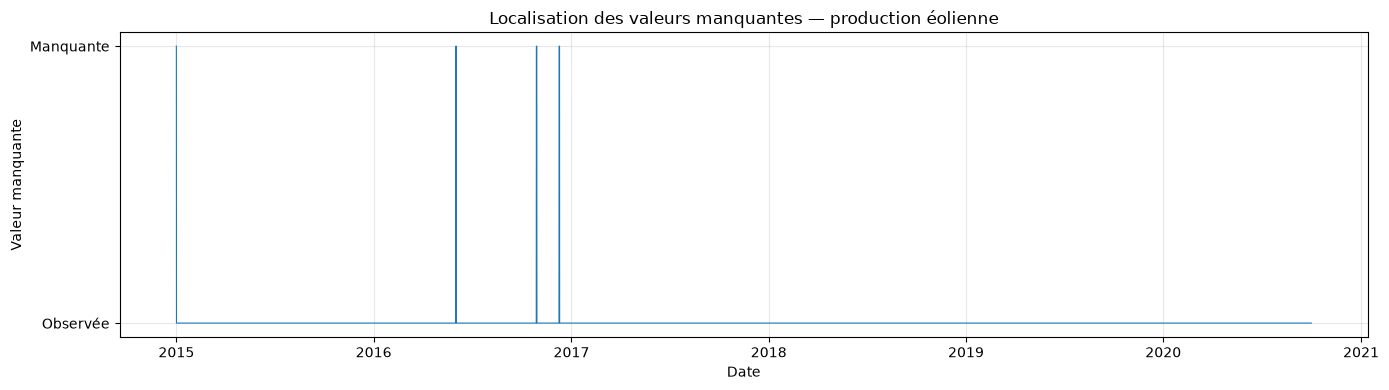

In [14]:
# Visualisation des valeurs manquantes dans la série éolienne

plt.figure(figsize=(14, 4))

plt.plot(
    df["utc_timestamp"],
    df[TARGET].isna().astype(int),
    linewidth=0.8
)

plt.xlabel("Date")
plt.ylabel("Valeur manquante")
plt.title("Localisation des valeurs manquantes — production éolienne")

plt.yticks([0, 1], ["Observée", "Manquante"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusion - Q1

Le jeu de données contient 50 401 observations horaires réparties sur la période allant du 31 décembre 2014 à 23:00 UTC au 30 septembre 2020 à 23:00 UTC. Les horodatages sont parfaitement réguliers : deux observations consécutives sont toujours séparées d'une heure.

La variable étudiée, `DE_wind_onshore_generation_actual`, présente 73 valeurs manquantes, soit 0,14 % des observations. Ces valeurs ne sont pas réparties uniformément dans le temps : elles sont regroupées en quatre séquences, dont une seule valeur isolée et trois séquences de 24 heures consécutives.

Cette structure conduit à distinguer les lacunes courtes des lacunes longues. Une interpolation temporelle peut être envisagée pour la lacune isolée d'une heure, tandis que les trois séquences de 24 heures doivent être traitées avec davantage de prudence afin de ne pas créer artificiellement une trajectoire de production sur une journée complète.

Pour l'évaluation des modèles de prévision, les observations réellement manquantes devront être prises en compte afin d'éviter qu'une imputation arbitraire ne donne une information artificielle au modèle ou ne modifie artificiellement les performances mesurées.

## Question 2 : Découpage chronologique des données

Pour évaluer correctement les modèles de prévision, nous séparons la série en trois périodes successives :

- 70 % des données pour l'entraînement ;
- 15 % des données pour la validation ;
- 15 % des données pour le test.

Le découpage respecte l'ordre chronologique des observations. Les données d'entraînement correspondent donc au passé le plus ancien, les données de validation viennent ensuite et les données de test correspondent à la période la plus récente.

Ce choix reproduit une situation réelle de prévision : le modèle utilise les informations disponibles dans le passé pour prévoir des valeurs futures.

Un découpage aléatoire n'est pas adapté à une série temporelle, car il pourrait mélanger des observations anciennes et futures entre les différents ensembles. Cela pourrait provoquer une fuite d'information (*data leakage*) et donner une évaluation trop optimiste des performances.

Le jeu de test doit donc rester séparé des données utilisées pour construire et ajuster les modèles.

In [20]:
# Découpage chronologique des données

n = len(df)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train = df.iloc[:train_end].copy()
validation = df.iloc[train_end:validation_end].copy()
test = df.iloc[validation_end:].copy()

print("Nombre total d'observations :", n)

print("\nTaille de l'entraînement :", len(train))
print("Taille de la validation  :", len(validation))
print("Taille du test          :", len(test))

print("\nPériode d'entraînement :")
print(train["utc_timestamp"].min(), "→", train["utc_timestamp"].max())

print("\nPériode de validation :")
print(validation["utc_timestamp"].min(), "→", validation["utc_timestamp"].max())

print("\nPériode de test :")
print(test["utc_timestamp"].min(), "→", test["utc_timestamp"].max())

Nombre total d'observations : 50401

Taille de l'entraînement : 35280
Taille de la validation  : 7560
Taille du test          : 7561

Période d'entraînement :
2014-12-31 23:00:00+00:00 → 2019-01-09 22:00:00+00:00

Période de validation :
2019-01-09 23:00:00+00:00 → 2019-11-20 22:00:00+00:00

Période de test :
2019-11-20 23:00:00+00:00 → 2020-09-30 23:00:00+00:00


### Interprétation

Le découpage respecte bien l'ordre chronologique des données. L'entraînement correspond à la période la plus ancienne, puis viennent la validation et enfin le test.

Les trois ensembles sont bien séparés. Le jeu de test représente donc une période future par rapport aux données utilisées pour construire et ajuster les modèles.

## Question 3 : Modèle naïf saisonnier à 24 heures

Pour avoir une première référence, on utilise un modèle naïf avec une saisonnalité de 24 heures. Pour prévoir une heure donnée, on reprend simplement la valeur observée à la même heure la veille.

On évalue ce modèle sur plusieurs origines de prévision pour respecter l'ordre temporel des données.

On mesure ensuite les performances avec la MAE et la MASE, puis on calcule un intervalle de confiance à 95 % pour la MASE.

In [21]:
# Modèle naïf saisonnier à 24 heures

TARGET = "DE_wind_onshore_generation_actual"
SEASONAL_PERIOD = 24

test_naive = test[["utc_timestamp", TARGET]].copy()

test_naive["naive_24h"] = test_naive[TARGET].shift(SEASONAL_PERIOD)

print("Nombre d'observations du test :", len(test_naive))
print("Nombre de prévisions disponibles :", test_naive["naive_24h"].notna().sum())

Nombre d'observations du test : 7561
Nombre de prévisions disponibles : 7537


In [22]:
from sklearn.metrics import mean_absolute_error

# On garde uniquement les lignes où la prévision est disponible
evaluation_naive = test_naive.dropna(subset=["naive_24h"])

mae_naive = mean_absolute_error(
    evaluation_naive[TARGET],
    evaluation_naive["naive_24h"]
)

print(f"MAE du modèle naïf à 24 h : {mae_naive:.2f} MW")

MAE du modèle naïf à 24 h : 6113.15 MW


In [23]:
# Vérification des valeurs utilisées pour l'évaluation
print(evaluation_naive[[TARGET, "naive_24h"]].describe())

       DE_wind_onshore_generation_actual     naive_24h
count                        7537.000000   7537.000000
mean                        11910.384503  11913.310468
std                          9605.417882   9602.045349
min                           119.000000    119.000000
25%                          4218.000000   4221.000000
50%                          8902.000000   8902.000000
75%                         17640.000000  17640.000000
max                         40752.000000  40752.000000


In [24]:
# Vérification des premières prévisions
print("\nQuelques observations :")
print(evaluation_naive[[TARGET, "naive_24h"]].head(10))


Quelques observations :
       DE_wind_onshore_generation_actual  naive_24h
42864                             5441.0     1993.0
42865                             5586.0     2050.0
42866                             5629.0     2077.0
42867                             6092.0     2067.0
42868                             6583.0     2153.0
42869                             6698.0     2299.0
42870                             7115.0     2426.0
42871                             7246.0     2648.0
42872                             7263.0     2627.0
42873                             6803.0     2776.0


### Calcul de la MASE

La MASE permet de comparer l'erreur du modèle à celle d'une prévision naïve saisonnière sur les données d'entraînement. Une MASE inférieure à 1 signifie que le modèle fait moins d'erreurs que cette référence. Une valeur supérieure à 1 signifie que son erreur est plus élevée.

In [25]:
# Calcul de l'erreur de référence sur l'entraînement

train_values = train[TARGET].dropna()

naive_errors_train = (
    train_values.iloc[SEASONAL_PERIOD:].to_numpy()
    - train_values.iloc[:-SEASONAL_PERIOD].to_numpy()
)

scale = abs(naive_errors_train).mean()

print(f"Erreur absolue moyenne de référence : {scale:.2f} MW")

Erreur absolue moyenne de référence : 4991.74 MW


In [26]:
# Calcul de la MASE

mae_naive = mean_absolute_error(
    evaluation_naive[TARGET],
    evaluation_naive["naive_24h"]
)

mase_naive = mae_naive / scale

print(f"MAE du modèle naïf à 24 h : {mae_naive:.2f} MW")
print(f"MASE du modèle naïf à 24 h : {mase_naive:.3f}")

MAE du modèle naïf à 24 h : 6113.15 MW
MASE du modèle naïf à 24 h : 1.225


### Interprétation

La MASE obtenue est de 1,225. L'erreur du modèle naïf sur le jeu de test est donc plus élevée que l'erreur de référence calculée sur les données d'entraînement. Le modèle naïf à 24 heures constitue ainsi une première référence pour comparer les modèles suivants.

### Intervalle de confiance à 95 % de la MASE

On utilise un bootstrap pour estimer un intervalle de confiance à 95 % de la MASE. On rééchantillonne les erreurs du modèle sur le jeu de test afin d'obtenir une estimation de la variabilité de cette mesure.

In [27]:
def start_timer():
    start_datetime = datetime.now()
    start_counter = perf_counter()
    return start_datetime, start_counter

In [28]:
# Bootstrap par blocs pour l'intervalle de confiance de la MASE

import numpy as np
from time import perf_counter
from datetime import datetime

start_datetime, start_counter = start_timer()

errors = (
    evaluation_naive[TARGET].to_numpy()
    - evaluation_naive["naive_24h"].to_numpy()
)
absolute_errors = np.abs(errors)

block_size = 24
n_bootstrap = 1000
n = len(absolute_errors)

rng = np.random.default_rng(42)
bootstrap_mase = []

for _ in range(n_bootstrap):
    sampled = []

    while len(sampled) < n:
        start = rng.integers(0, n - block_size + 1)
        sampled.extend(absolute_errors[start:start + block_size])

    sampled = np.array(sampled[:n])
    bootstrap_mase.append(sampled.mean() / scale)

ci_low, ci_high = np.percentile(bootstrap_mase, [2.5, 97.5])

print(f"MASE : {mase_naive:.3f}")
print(f"IC à 95 % : [{ci_low:.3f} ; {ci_high:.3f}]")

MASE : 1.225
IC à 95 % : [1.137 ; 1.325]


### Vérification de l'alignement des prévisions

On utilise les 24 dernières heures de la validation comme historique pour commencer les prévisions sur le test. On conserve ensuite uniquement les observations du test pour calculer les erreurs.

In [29]:
# On réunit la validation et le test dans l'ordre chronologique
validation_test = pd.concat(
    [validation[["utc_timestamp", TARGET]],
     test[["utc_timestamp", TARGET]]]
).copy()

# Prévision naïve : valeur observée 24 heures auparavant
validation_test["naive_24h"] = (
    validation_test[TARGET].shift(24)
)

# On conserve uniquement les dates du test
test_naive = validation_test[
    validation_test["utc_timestamp"].isin(test["utc_timestamp"])
].copy()

# On garde les prévisions pour lesquelles la valeur réelle
# et la valeur de référence sont disponibles
evaluation_naive = test_naive.dropna(
    subset=[TARGET, "naive_24h"]
).copy()

print("Observations du test :", len(test))
print("Prévisions évaluables :", len(evaluation_naive))
print("Première date évaluée :", evaluation_naive["utc_timestamp"].min())
print("Dernière date évaluée :", evaluation_naive["utc_timestamp"].max())

Observations du test : 7561
Prévisions évaluables : 7561
Première date évaluée : 2019-11-20 23:00:00+00:00
Dernière date évaluée : 2020-09-30 23:00:00+00:00


In [30]:
from datetime import datetime
from time import perf_counter
import numpy as np
from sklearn.metrics import mean_absolute_error

# 1. MAE sur le test
mae_naive = mean_absolute_error(
    evaluation_naive[TARGET],
    evaluation_naive["naive_24h"]
)

# 2. Échelle de référence sur l'entraînement
train_values = train[TARGET]
train_lag24 = train_values.shift(24)

valid_pairs = train_values.notna() & train_lag24.notna()

scale = np.mean(
    np.abs(
        train_values[valid_pairs].to_numpy()
        - train_lag24[valid_pairs].to_numpy()
    )
)

# 3. MASE
mase_naive = mae_naive / scale

# 4. Bootstrap par blocs des erreurs absolues
errors = np.abs(
    evaluation_naive[TARGET].to_numpy()
    - evaluation_naive["naive_24h"].to_numpy()
)

block_size = 24
n_bootstrap = 1000
rng = np.random.default_rng(42)
n = len(errors)
n_blocks = int(np.ceil(n / block_size))

bootstrap_mase = []

for _ in range(n_bootstrap):
    starts = rng.integers(0, n - block_size + 1, size=n_blocks)
    sample = np.concatenate([
        errors[start:start + block_size]
        for start in starts
    ])[:n]

    bootstrap_mase.append(np.mean(sample) / scale)

ic_low, ic_high = np.quantile(
    bootstrap_mase, [0.025, 0.975]
)

# 5. Résultats
print(f"Nombre de prévisions : {n}")
print(f"MAE : {mae_naive:.2f} MW")
print(f"Échelle d'entraînement : {scale:.2f} MW")
print(f"MASE : {mase_naive:.3f}")
print(f"IC à 95 % : [{ic_low:.3f} ; {ic_high:.3f}]")


Nombre de prévisions : 7561
MAE : 6100.71 MW
Échelle d'entraînement : 4996.19 MW
MASE : 1.221
IC à 95 % : [1.136 ; 1.314]


### Interprétation

Le modèle naïf saisonnier obtient une MAE de 6 100,71 MW et une MASE de 1,221 sur les 7 561 observations du test.

La MASE est supérieure à 1 : l'erreur du modèle sur le test dépasse l'erreur saisonnière moyenne de référence calculée sur l'entraînement.

L'intervalle de confiance bootstrap à 95 % est [1,136 ; 1,314]. Il traduit l'incertitude liée à l'estimation de la MASE, selon le rééchantillonnage par blocs utilisé.

## Question 4 — Prévision avec Gradient Boosting

### Objectif et méthode

L'objectif est d'évaluer les performances d'un modèle Gradient Boosting pour prévoir la production éolienne une heure à l'avance, et de les comparer à celles du modèle naïf saisonnier.

Pour cela, on construit des variables explicatives à partir des valeurs passées de production et du calendrier. Les retards sont calculés sur la série chronologique complète afin de conserver les observations précédant les frontières entre entraînement, validation et test.

Le modèle est entraîné uniquement sur la période d'entraînement. Les observations présentant des valeurs manquantes dans les variables explicatives ou la cible sont exclues de l'apprentissage.

Deux approches sont étudiées : la prédiction directe du niveau de production et la prédiction de sa variation entre deux heures consécutives.

In [31]:
from datetime import datetime
from time import perf_counter
import numpy as np
import pandas as pd

# On travaille uniquement avec la date et la production éolienne
data = df[["utc_timestamp", TARGET]].copy()
data = data.sort_values("utc_timestamp").reset_index(drop=True)

# Variables calendaires
data["hour"] = data["utc_timestamp"].dt.hour
data["dayofweek"] = data["utc_timestamp"].dt.dayofweek
data["month"] = data["utc_timestamp"].dt.month

# Variables retardées : production passée
lags = [1, 2, 3, 24, 48, 168]

for lag in lags:
    data[f"lag_{lag}"] = data[TARGET].shift(lag)

# Variables cycliques pour représenter les répétitions du calendrier
data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)

data["day_sin"] = np.sin(2 * np.pi * data["dayofweek"] / 7)
data["day_cos"] = np.cos(2 * np.pi * data["dayofweek"] / 7)

# Définir les variables explicatives et la cible
FEATURES = [
    "hour", "dayofweek", "month",
    "hour_sin", "hour_cos", "day_sin", "day_cos",
    "lag_1", "lag_2", "lag_3",
    "lag_24", "lag_48", "lag_168"
]

# Retrouver les frontières chronologiques
train_end_time = train["utc_timestamp"].max()
validation_end_time = validation["utc_timestamp"].max()

# Séparer les lignes selon leur date
train_gb = data[data["utc_timestamp"] <= train_end_time].copy()
validation_gb = data[
    (data["utc_timestamp"] > train_end_time)
    & (data["utc_timestamp"] <= validation_end_time)
].copy()
test_gb = data[data["utc_timestamp"] > validation_end_time].copy()

# Retirer les lignes incomplètes pour les variables nécessaires
train_gb = train_gb.dropna(subset=FEATURES + [TARGET])
validation_gb = validation_gb.dropna(subset=FEATURES + [TARGET])
test_gb = test_gb.dropna(subset=FEATURES + [TARGET])

# Résultats
print("Lignes d'entraînement :", len(train_gb))
print("Lignes de validation :", len(validation_gb))
print("Lignes de test :", len(test_gb))
print("Nombre de variables :", len(FEATURES))

Lignes d'entraînement : 34823
Lignes de validation : 7560
Lignes de test : 7561
Nombre de variables : 13


### Entraînement du Gradient Boosting

On utilise un modèle de régression par Gradient Boosting. Il construit progressivement des arbres de décision afin de réduire les erreurs de prédiction.

On commence avec des paramètres fixes pour établir une première référence. La validation permettra ensuite d'examiner les performances avant toute évaluation finale sur le test.

In [34]:
from datetime import datetime
from time import perf_counter
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# Préparer les données d'entraînement et de validation
X_train = train_gb[FEATURES]
y_train = train_gb[TARGET]

X_val = validation_gb[FEATURES]
y_val = validation_gb[TARGET]

# Définir le modèle
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    loss="squared_error",
    random_state=42
)

# Entraîner le modèle
gb_model.fit(X_train, y_train)

# Prévoir sur la validation
val_pred = gb_model.predict(X_val)

# Calculer la MAE de validation
mae_val_gb = mean_absolute_error(y_val, val_pred)

end_datetime = datetime.now()
duration = perf_counter() - start_counter

print(f"MAE validation : {mae_val_gb:.2f} MW")
#print(f"Durée : {duration:.2f} secondes")

MAE validation : 630.76 MW


In [35]:
start_counter = perf_counter()

mae_val_naive = mean_absolute_error(
    validation_gb[TARGET],
    validation_gb["lag_24"]
)

print(f"MAE naïve validation : {mae_val_naive:.2f} MW")
print(f"MAE Gradient Boosting validation : {mae_val_gb:.2f} MW")

MAE naïve validation : 5371.65 MW
MAE Gradient Boosting validation : 630.76 MW


In [36]:
# Q4 — Importance des variables
# Identifier les variables les plus utilisées par le modèle

feature_importance = pd.DataFrame({
    "variable": FEATURES,
    "importance": gb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance", ascending=False
)

display(feature_importance)

,variable,importance
7,lag_1,0.998183
9,lag_3,0.001478
8,lag_2,0.000196
3,hour_sin,0.000071
0,hour,0.000068
2,month,0.000004
1,dayofweek,0.000000
4,hour_cos,0.000000
6,day_cos,0.000000
5,day_sin,0.000000


In [37]:
# Q4 — Comparaison avec le modèle naïf à 1 heure
# vérifier si le Gradient Boosting fait mieux que la simple persistance.

mae_val_naive_1h = mean_absolute_error(
    validation_gb[TARGET],
    validation_gb["lag_1"]
)

print(f"MAE naïve à 1 h : {mae_val_naive_1h:.2f} MW")
print(f"MAE Gradient Boosting : {mae_val_gb:.2f} MW")

MAE naïve à 1 h : 696.68 MW
MAE Gradient Boosting : 630.76 MW


### Variante - Prédiction de la variation

On entraîne un second Gradient Boosting pour prévoir la variation de production entre deux heures consécutives. On ajoute ensuite cette variation prédite à la dernière production observée pour obtenir la prévision du niveau.

In [38]:
# Q4 — Gradient Boosting sur la variation
# Apprendre la correction à apporter à la dernière valeur observée.

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from time import perf_counter

# Construire la variation horaire de la production
data["delta_target"] = data[TARGET] - data[TARGET].shift(1)

# Préparer les données selon les mêmes périodes chronologiques
train_delta = data[data["utc_timestamp"] <= train_end_time].copy()
validation_delta = data[
    (data["utc_timestamp"] > train_end_time)
    & (data["utc_timestamp"] <= validation_end_time)
].copy()

# Retirer les lignes incomplètes
train_delta = train_delta.dropna(
    subset=FEATURES + ["delta_target", TARGET, "lag_1"]
)
validation_delta = validation_delta.dropna(
    subset=FEATURES + ["delta_target", TARGET, "lag_1"]
)

# Définir et entraîner le modèle
gb_delta_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    loss="squared_error",
    random_state=42
)

gb_delta_model.fit(
    train_delta[FEATURES],
    train_delta["delta_target"]
)

# Prévoir la variation puis reconstruire le niveau
delta_pred = gb_delta_model.predict(validation_delta[FEATURES])
val_pred_delta = validation_delta["lag_1"].to_numpy() + delta_pred

# Évaluer la prévision reconstruite
mae_val_delta = mean_absolute_error(
    validation_delta[TARGET],
    val_pred_delta
)

duration = perf_counter() - start_counter

print(f"MAE Gradient Boosting sur variation : {mae_val_delta:.2f} MW")
print("Lignes de validation :", len(validation_delta))

MAE Gradient Boosting sur variation : 559.09 MW
Lignes de validation : 7560


### Interprétation : Prédiction de la variation

Le modèle qui prédit la variation obtient une MAE de 559,09 MW, contre 630,76 MW pour le modèle qui prédit directement le niveau.

La prédiction de la variation réduit donc la MAE d'environ 11,4 % sur la validation. Cette formulation semble mieux adaptée à cette série, mais il faudra vérifier si ce gain se maintient sur le jeu de test.

### Interprétation et limites (Question 4)

Deux formulations du Gradient Boosting ont été comparées sur l'ensemble de validation : la prédiction directe du niveau de production et la prédiction de sa variation horaire.

Les résultats obtenus sont les suivants :

| Modèle | MAE (MW) |
|---|---:|
| Gradient Boosting - niveau brut | 630,76 |
| Gradient Boosting - variation | 559,09 |

La formulation par variation réduit la MAE d'environ **11,4 %** par rapport à la prédiction directe du niveau.

Cette amélioration suggère qu'il est pertinent, pour ces données, d'estimer la variation horaire puis de reconstruire la prévision à partir de la dernière production observée.

L'analyse de l'importance des variables du modèle prédisant le niveau brut met également en évidence le rôle majeur de `lag_1`, ce qui confirme l'intérêt des observations récentes pour la prévision à court terme. Ces importances restent toutefois descriptives et ne permettent pas de conclure à un effet causal.

Ces résultats doivent être interprétés avec certaines précautions :

- Les performances dépendent des variables explicatives, des hyperparamètres et de la période de validation.
- Les retards temporels doivent utiliser exclusivement des observations disponibles avant l'instant prévu.
- Les valeurs manquantes doivent être prises en compte afin d'éviter de calculer des variations entre des observations non consécutives.
- La comparaison des deux formulations doit porter sur les mêmes instants de validation.

**Sur cette période de validation, le Gradient Boosting prédisant la variation présente les meilleures performances parmi les deux formulations étudiées.** Il est donc retenu pour les comparaisons suivantes, sous réserve d'une évaluation finale sur le jeu de test indépendant.

## Question 5 : Comparaison statistique avec le test de Diebold-Mariano

### Objectif

L’objectif de cette question est de comparer statistiquement les performances de la baseline naïve et du modèle Gradient Boosting. La comparaison descriptive des erreurs permet de mesurer leur écart, mais elle ne suffit pas à déterminer si cet écart est statistiquement significatif.

On utilise le **test de Diebold-Mariano (DM)**, qui permet de comparer les performances prédictives de deux modèles à partir de leurs erreurs calculées aux mêmes dates.

### Principe du test

Le test repose sur la différence entre les pertes associées aux deux modèles. On utilise ici la **perte quadratique**, c’est-à-dire le carré de l’erreur de prévision.

On note :

* $y_t$ : la production éolienne réellement observée à la date $t$ ;
* $\widehat{y}_{N,t}$ : la prévision de la baseline naïve ;
* $\widehat{y}_{GB,t}$ : la prévision du Gradient Boosting.

Les erreurs de prévision sont :

$$
e_{N,t}=y_t-\widehat y_{N,t}
$$

$$
e_{GB,t}=y_t-\widehat y_{GB,t}
$$

La différence de pertes quadratiques est définie par :

$$
d_t=e_{N,t}^{2}-e_{GB,t}^{2}
$$

Une différence positive signifie que la baseline naïve a une erreur quadratique plus élevée à cette date. Une différence négative signifie que le Gradient Boosting a une erreur quadratique plus élevée.

### Hypothèses statistiques

On cherche à tester si la différence moyenne des pertes quadratiques est nulle.

* **Hypothèse nulle $H_0$** : les deux modèles ont la même perte quadratique moyenne, soit $E[d_t]=0$.
* **Hypothèse alternative $H_1$** : les deux modèles ont des pertes quadratiques moyennes différentes, soit $E[d_t]\neq 0$.

On retient un **test bilatéral au seuil de 5 %** :

$$
\alpha=0{,}05
$$

Le test est bilatéral, car on cherche à détecter une différence dans les deux sens, sans supposer à l’avance quel modèle sera le plus performant.

### Statistique de Diebold-Mariano

La statistique du test est construite à partir de la moyenne des différences de pertes et de son erreur-type :

$$
DM=\frac{\bar d}{\sqrt{\widehat{\operatorname{Var}}(\bar d)}}
$$

où $\bar d$ désigne la moyenne des différences de pertes quadratiques.

Les erreurs de prévision d'une série temporelle peuvent être dépendantes. La variance doit donc tenir compte de l’autocorrélation éventuelle des différences de pertes. Dans cette étude, on utilise une estimation robuste de type **HAC (Newey-West)**, avec un retard maximal fixé à 24 observations, correspondant à une journée de données horaires.

Sous l’hypothèse nulle, la statistique est comparée à une loi normale centrée réduite, dans le cadre de l’approximation asymptotique.

### Méthodologie

La comparaison est réalisée sur l’ensemble de validation, en utilisant les prévisions obtenues aux mêmes origines et pour le même horizon.

Les étapes sont les suivantes :

1. Récupérer les prévisions de la baseline naïve et du Gradient Boosting.
2. Aligner les deux séries de prévisions sur leurs dates communes.
3. Écarter les observations pour lesquelles une prévision ou la valeur réelle est manquante.
4. Calculer les erreurs quadratiques et leur différence à chaque date.
5. Calculer la statistique DM, sa p-value et conclure au seuil de 5 %.

La baseline doit correspondre à celle définie dans le protocole expérimental. Pour cette comparaison, on utilise la baseline saisonnière à 24 heures si c’est bien la référence retenue dans la question précédente.

### Règle de décision

La décision repose sur la p-value :

* Si $p<0{,}05$, on rejette l’hypothèse nulle : les pertes quadratiques moyennes sont statistiquement différentes au seuil de 5 %.
* Si $p\geq 0{,}05$, on ne rejette pas l’hypothèse nulle : les données ne fournissent pas suffisamment d’éléments pour conclure à une différence statistiquement significative.

Le signe de la statistique DM permet ensuite d’identifier le sens de la différence :

* \(DM>0\) : la perte moyenne de la baseline est supérieure à celle du Gradient Boosting.
* \(DM<0\) : la perte moyenne du Gradient Boosting est supérieure à celle de la baseline.

### Précautions d’interprétation

Le test compare les pertes quadratiques moyennes et non directement les MAE. Une différence de MAE observée précédemment ne garantit donc pas que le test DM sera significatif.

Par ailleurs, ne pas rejeter l’hypothèse nulle ne signifie pas que les modèles sont équivalents. Cela signifie seulement que les données et le test utilisés ne permettent pas de mettre en évidence une différence statistiquement significative.

Enfin, le choix du retard HAC est un choix méthodologique qui doit être indiqué et peut faire l’objet d’une analyse de sensibilité. Le test est ici appliqué aux prévisions de validation ; l’ensemble de test reste réservé à l’évaluation finale du modèle retenu.


In [39]:
# Q5 — Test de Diebold-Mariano
# Comparer les pertes quadratiques sur les mêmes dates.

import numpy as np
import pandas as pd
from scipy.stats import norm

# Préparer les prévisions du Gradient Boosting
gb_results = validation_delta[
    ["utc_timestamp", TARGET]
].copy()

gb_results["gb_forecast"] = val_pred_delta

# Préparer la baseline saisonnière (retard de 24 heures)
naive_results = data[["utc_timestamp", TARGET]].copy()
naive_results["naive_forecast"] = naive_results[TARGET].shift(24)

# Garder uniquement les dates de validation du Gradient Boosting
naive_results = naive_results[
    naive_results["utc_timestamp"].isin(gb_results["utc_timestamp"])
]

# Aligner les deux modèles sur les mêmes dates
comparison = gb_results.merge(
    naive_results[["utc_timestamp", "naive_forecast"]],
    on="utc_timestamp",
    how="inner"
)

comparison = comparison.dropna(
    subset=[TARGET, "gb_forecast", "naive_forecast"]
).sort_values("utc_timestamp")

# Calcul des erreurs et des différences de pertes quadratiques
comparison["error_naive"] = (
    comparison[TARGET] - comparison["naive_forecast"]
)
comparison["error_gb"] = (
    comparison[TARGET] - comparison["gb_forecast"]
)

comparison["d"] = (
    comparison["error_naive"] ** 2
    - comparison["error_gb"] ** 2
)

# Statistique DM avec variance HAC (Newey-West)
d = comparison["d"].to_numpy()
n = len(d)
mean_d = np.mean(d)

# Retard HAC fixé à 24 heures pour tenir compte
# d'une éventuelle dépendance à l'échelle journalière.
lag = 24
u = d - mean_d

gamma_0 = np.dot(u, u) / n
long_run_variance = gamma_0

for k in range(1, lag + 1):
    gamma_k = np.dot(u[k:], u[:-k]) / n
    weight = 1 - k / (lag + 1)
    long_run_variance += 2 * weight * gamma_k

variance_mean = long_run_variance / n
dm_stat = mean_d / np.sqrt(variance_mean)
p_value = 2 * (1 - norm.cdf(abs(dm_stat)))

alpha = 0.05

print("Nombre de dates comparées :", n)
print(f"Différence moyenne des pertes : {mean_d:.2f} MW²")
print(f"Statistique DM : {dm_stat:.4f}")
print(f"p-value : {p_value:.6f}")
print(f"Seuil de significativité : {alpha}")

if p_value < alpha:
    print("Conclusion : rejet de H0 au seuil de 5 %.")
else:
    print("Conclusion : on ne rejette pas H0 au seuil de 5 %.")

Nombre de dates comparées : 7560
Différence moyenne des pertes : 51448174.97 MW²
Statistique DM : 13.7839
p-value : 0.000000
Seuil de significativité : 0.05
Conclusion : rejet de H0 au seuil de 5 %.


### Interprétation — Test de Diebold-Mariano

Le test de Diebold-Mariano permet de comparer les performances prédictives de la baseline saisonnière et du modèle Gradient Boosting à partir de leurs pertes quadratiques, calculées sur **7 560 observations communes de validation**.

Les résultats obtenus sont les suivants :

- **Différence moyenne des pertes quadratiques :** 51 448 174,97 MW².
- **Statistique de Diebold-Mariano :** 13,7839.
- **p-value :** inférieure à 0,001.
- **Seuil de significativité :** 5 %.

La variance à long terme est estimée par une méthode **HAC**, avec un retard maximal de 24 heures.

La différence moyenne des pertes étant positive, la baseline saisonnière présente une perte quadratique moyenne supérieure à celle du Gradient Boosting. La p-value étant inférieure au seuil de 5 %, nous rejetons l'hypothèse nulle d'égalité des pertes quadratiques moyennes.

**Le Gradient Boosting présente donc une perte quadratique moyenne significativement plus faible que celle de la baseline saisonnière sur la période de validation.**

Ce résultat complète la comparaison descriptive fondée sur les métriques d'erreur, notamment la MAE. Il reste toutefois lié à la période étudiée, à l'horizon de prévision, à la fonction de perte quadratique et au choix de l'estimateur HAC.

La significativité statistique observée sur la validation ne garantit pas une supériorité systématique sur d'autres périodes. L'évaluation finale doit donc être réalisée sur le **jeu de test**, conservé indépendant des choix méthodologiques.

## Question 6 : Prévisions probabilistes et évaluation de l'incertitude

### Objectif

Jusqu'à présent, on a utilisé des prévisions ponctuelles, qui donnent une seule valeur prévue pour chaque heure. Dans cette question, on cherche aussi à représenter l'incertitude autour de cette prévision à l'aide de quantiles.

On construit un **intervalle prédictif central à 80 %** à partir des quantiles 10 % et 90 % :

$$
I_{80\%,t}=[q_{0.10,t},q_{0.90,t}]
$$

On compare deux approches probabilistes : la baseline saisonnière naïve et le Gradient Boosting.

### Baseline saisonnière

Pour la baseline, on calcule sur l'entraînement les écarts entre la production observée et celle observée 24 heures auparavant :

$$
r_t=y_t-y_{t-24}
$$

On estime ensuite les quantiles empiriques 10 % et 90 % de ces écarts. Ils sont ajoutés à la prévision saisonnière \(y_{t-24}\) pour construire les deux bornes :

$$
q_{0.10,t}=y_{t-24}+Q_{0.10}(r)
$$

$$
q_{0.90,t}=y_{t-24}+Q_{0.90}(r)
$$

Les quantiles des écarts sont calculés uniquement sur l'entraînement afin de ne pas utiliser les observations de validation pour construire les prévisions.

### Gradient Boosting quantile

Pour le Gradient Boosting, on utilise une fonction de perte quantile. Deux modèles sont entraînés séparément : un pour prévoir le quantile à 10 % et un autre pour le quantile à 90 %.

Contrairement à la baseline, qui utilise les mêmes quantiles d'écarts pour toutes les heures, le Gradient Boosting peut adapter les bornes aux variables explicatives disponibles.

### Évaluation avec la pinball loss

La qualité d'une prévision quantile est évaluée avec la **pinball loss**. Pour un quantile de niveau \(\tau\), elle pénalise différemment une prévision située au-dessus ou au-dessous de la valeur observée.

$$
L_\tau(y,q_\tau)=
\begin{cases}
\tau(y-q_\tau), & \text{si } y\geq q_\tau \\
(1-\tau)(q_\tau-y), & \text{si } y<q_\tau
\end{cases}
$$

Une pinball loss plus faible indique une meilleure prévision du quantile. On calcule la perte pour les quantiles 10 % et 90 %, puis leur moyenne.

### Couverture empirique

On calcule également la proportion d'observations réellement comprises entre les deux bornes :

$$
\widehat C=
\frac{1}{n}
\sum_{t=1}^{n}
\mathbf{1}
\{q_{0.10,t}\leq y_t\leq q_{0.90,t}\}
$$

Comme l'intervalle est construit à 80 %, son **niveau nominal est de 80 %**. On compare donc la couverture observée à cette valeur.

Une couverture inférieure à 80 % correspond à une sous-couverture, tandis qu'une couverture supérieure à 80 % correspond à une sur-couverture. La couverture doit cependant être interprétée avec la pinball loss, car un intervalle très large peut couvrir beaucoup d'observations sans être très informatif.

### Méthodologie

Les quantiles sont estimés uniquement à partir de l'entraînement et les deux modèles sont évalués sur les mêmes observations de validation. On calcule pour chaque modèle la pinball loss moyenne, la couverture empirique de l'intervalle à 80 % et son écart par rapport au niveau nominal.

Cette démarche permet de comparer non seulement la précision des prévisions, mais aussi la manière dont chaque modèle représente l'incertitude.

In [40]:
# Q6 — Prévisions probabilistes de la baseline saisonnière
# Objectif : construire les quantiles 10 % et 90 % en respectant
# l'historique disponible aux frontières des périodes.

# Calcul du retard saisonnier sur toute la série
data["seasonal_lag_24"] = data[TARGET].shift(24)

# Écarts saisonniers calculés uniquement sur l'entraînement
train_prob = data[
    data["utc_timestamp"] <= train_end_time
].copy()

train_prob["seasonal_error"] = (
    train_prob[TARGET] - train_prob["seasonal_lag_24"]
)

seasonal_errors = train_prob["seasonal_error"].dropna()

# Quantiles empiriques des écarts saisonniers
q10_error = seasonal_errors.quantile(0.10)
q90_error = seasonal_errors.quantile(0.90)

# Sélection de la validation après le calcul du retard
validation_prob = data[
    (data["utc_timestamp"] > train_end_time)
    & (data["utc_timestamp"] <= validation_end_time)
].copy()

# Bornes de l'intervalle prédictif à 80 %
validation_prob["naive_q10"] = (
    validation_prob["seasonal_lag_24"] + q10_error
)

validation_prob["naive_q90"] = (
    validation_prob["seasonal_lag_24"] + q90_error
)

# Vérification
valid_naive_prob = validation_prob.dropna(
    subset=[TARGET, "naive_q10", "naive_q90"]
).copy()

print("Nombre d'écarts saisonniers d'entraînement :", len(seasonal_errors))
print(f"Quantile 10 % des écarts : {q10_error:.2f} MW")
print(f"Quantile 90 % des écarts : {q90_error:.2f} MW")
print("Observations de validation :", len(validation_prob))
print("Prévisions probabilistes évaluables :", len(valid_naive_prob))

Nombre d'écarts saisonniers d'entraînement : 35111
Quantile 10 % des écarts : -8066.00 MW
Quantile 90 % des écarts : 8212.00 MW
Observations de validation : 7560
Prévisions probabilistes évaluables : 7560


In [41]:
# Q6 — Évaluation probabiliste de la baseline saisonnière
# Objectif : calculer la pinball loss et la couverture empirique
# de l'intervalle prédictif à 80 %.

from sklearn.metrics import mean_pinball_loss

y_true = valid_naive_prob[TARGET]

# Pinball loss pour les deux quantiles
pinball_q10_naive = mean_pinball_loss(
    y_true,
    valid_naive_prob["naive_q10"],
    alpha=0.10
)

pinball_q90_naive = mean_pinball_loss(
    y_true,
    valid_naive_prob["naive_q90"],
    alpha=0.90
)

# Moyenne des deux pinball losses
pinball_mean_naive = (
    pinball_q10_naive + pinball_q90_naive
) / 2

# Vérifier si chaque observation appartient à l'intervalle
inside_interval = (
    (y_true >= valid_naive_prob["naive_q10"])
    & (y_true <= valid_naive_prob["naive_q90"])
)

# Couverture empirique
coverage_naive = inside_interval.mean()

# Écart au niveau nominal de 80 %
nominal_coverage = 0.80
coverage_gap_naive = coverage_naive - nominal_coverage

print(f"Pinball loss q10 : {pinball_q10_naive:.2f} MW")
print(f"Pinball loss q90 : {pinball_q90_naive:.2f} MW")
print(f"Pinball loss moyenne : {pinball_mean_naive:.2f} MW")
print(f"Couverture empirique : {coverage_naive * 100:.2f} %")
print(f"Niveau nominal : {nominal_coverage * 100:.0f} %")
print(
    f"Écart au niveau nominal : "
    f"{coverage_gap_naive * 100:+.2f} points"
)

Pinball loss q10 : 1333.43 MW
Pinball loss q90 : 1331.40 MW
Pinball loss moyenne : 1332.42 MW
Couverture empirique : 77.63 %
Niveau nominal : 80 %
Écart au niveau nominal : -2.37 points


### Interprétation - Baseline probabiliste

La baseline saisonnière obtient une pinball loss moyenne de **1 332,42 MW**. La couverture empirique de l'intervalle prédictif à 80 % est de **77,63 %**, soit **2,37 points en dessous** du niveau nominal.

L'intervalle présente donc une légère sous-couverture sur la période de validation : les observations se trouvent un peu moins souvent que prévu entre les quantiles 10 % et 90 %.

Ces résultats serviront de référence pour évaluer les prévisions probabilistes du Gradient Boosting.

### Prévisions probabilistes avec Gradient Boosting

On entraîne deux modèles Gradient Boosting avec une fonction de perte quantile. Le premier estime le quantile à 10 % et le second le quantile à 90 %.

Ces deux quantiles définissent l'intervalle prédictif central à 80 %. Contrairement à la baseline saisonnière, dont les quantiles reposent sur une distribution globale des écarts historiques, le Gradient Boosting peut adapter les bornes de l'intervalle aux variables explicatives de chaque observation.

Les modèles sont entraînés uniquement sur l'ensemble d'entraînement et évalués sur la validation.

In [42]:
# Q6 — Gradient Boosting quantile
# Objectif : entraîner les modèles des quantiles 10 % et 90 %
# pour construire un intervalle prédictif à 80 %.

from sklearn.ensemble import GradientBoostingRegressor
from time import perf_counter

start_counter = perf_counter()

# Données d'entraînement
X_train_q = train_gb[FEATURES]
y_train_q = train_gb[TARGET]

# Données de validation
X_val_q = validation_gb[FEATURES]
y_val_q = validation_gb[TARGET]

# Modèle pour le quantile 10 %
gb_q10 = GradientBoostingRegressor(
    loss="quantile",
    alpha=0.10,
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Modèle pour le quantile 90 %
gb_q90 = GradientBoostingRegressor(
    loss="quantile",
    alpha=0.90,
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Entraînement
gb_q10.fit(X_train_q, y_train_q)
gb_q90.fit(X_train_q, y_train_q)

# Prévisions des deux quantiles sur la validation
gb_pred_q10 = gb_q10.predict(X_val_q)
gb_pred_q90 = gb_q90.predict(X_val_q)

duration = perf_counter() - start_counter

print("Nombre de prévisions :", len(y_val_q))
print(f"Durée d'exécution : {duration:.2f} secondes")

Nombre de prévisions : 7560
Durée d'exécution : 16.43 secondes


In [43]:
# Q6 — Vérification du croisement des quantiles
# Objectif : vérifier que le quantile 10 % ne dépasse jamais le quantile 90 %.

crossing = gb_pred_q10 > gb_pred_q90

n_crossing = crossing.sum()
rate_crossing = n_crossing / len(crossing)

print("Nombre de croisements :", n_crossing)
print(f"Taux de croisement : {rate_crossing * 100:.2f} %")

if n_crossing == 0:
    print("Aucun croisement : les intervalles sont correctement ordonnés.")
else:
    print("Attention : certains quantiles sont croisés.")

Nombre de croisements : 0
Taux de croisement : 0.00 %
Aucun croisement : les intervalles sont correctement ordonnés.


In [44]:
# Q6 — Évaluation probabiliste du Gradient Boosting
# Objectif : calculer la pinball loss et la couverture empirique
# de l'intervalle prédictif à 80 %.

from sklearn.metrics import mean_pinball_loss

# Pinball loss pour les quantiles 10 % et 90 %
pinball_q10_gb = mean_pinball_loss(
    y_val_q,
    gb_pred_q10,
    alpha=0.10
)

pinball_q90_gb = mean_pinball_loss(
    y_val_q,
    gb_pred_q90,
    alpha=0.90
)

# Moyenne des deux pinball losses
pinball_mean_gb = (
    pinball_q10_gb + pinball_q90_gb
) / 2

# Vérifier si les observations sont dans l'intervalle
inside_interval_gb = (
    (y_val_q.to_numpy() >= gb_pred_q10)
    & (y_val_q.to_numpy() <= gb_pred_q90)
)

# Couverture empirique
coverage_gb = inside_interval_gb.mean()

# Écart par rapport au niveau nominal de 80 %
nominal_coverage = 0.80
coverage_gap_gb = coverage_gb - nominal_coverage

# Affichage
print(f"Pinball loss q10 : {pinball_q10_gb:.2f} MW")
print(f"Pinball loss q90 : {pinball_q90_gb:.2f} MW")
print(f"Pinball loss moyenne : {pinball_mean_gb:.2f} MW")
print(f"Couverture empirique : {coverage_gb * 100:.2f} %")
print(f"Niveau nominal : {nominal_coverage * 100:.0f} %")
print(
    f"Écart au niveau nominal : "
    f"{coverage_gap_gb * 100:+.2f} points"
)

Pinball loss q10 : 289.58 MW
Pinball loss q90 : 173.34 MW
Pinball loss moyenne : 231.46 MW
Couverture empirique : 82.22 %
Niveau nominal : 80 %
Écart au niveau nominal : +2.22 points


### Interprétation des résultats probabilistes

Le Gradient Boosting obtient une pinball loss moyenne de **231,46 MW**, contre **1 332,42 MW** pour la baseline saisonnière. Sur cette période de validation, ses quantiles sont donc nettement mieux ajustés selon la pinball loss.

La couverture empirique du Gradient Boosting est de **82,22 %**, soit **2,22 points au-dessus** du niveau nominal de 80 %. La baseline atteint **77,63 %**, soit **2,37 points en dessous** du niveau nominal.

Les deux modèles présentent donc une couverture globale relativement proche de 80 %, mais dans des directions opposées : légère sous-couverture pour la baseline et légère sur-couverture pour le Gradient Boosting.

La couverture ne doit cependant pas être interprétée seule. Un intervalle très large peut obtenir une bonne couverture sans être suffisamment précis. La pinball loss apporte ici une information complémentaire et montre un avantage important du Gradient Boosting pour la prévision des quantiles sur l'ensemble de validation.

In [45]:
# Q6 — Diagnostic complémentaire : largeur des intervalles
# Objectif : comparer la précision des intervalles probabilistes
# en calculant leur largeur moyenne sur la validation.

# Largeur des intervalles de la baseline
width_naive = (
    valid_naive_prob["naive_q90"]
    - valid_naive_prob["naive_q10"]
)

# Largeur des intervalles du Gradient Boosting
width_gb = gb_pred_q90 - gb_pred_q10

# Statistiques descriptives
mean_width_naive = width_naive.mean()
mean_width_gb = width_gb.mean()

median_width_naive = width_naive.median()
median_width_gb = np.median(width_gb)

print("Baseline naïve")
print(f"Largeur moyenne : {mean_width_naive:.2f} MW")
print(f"Largeur médiane : {median_width_naive:.2f} MW")

print("\nGradient Boosting")
print(f"Largeur moyenne : {mean_width_gb:.2f} MW")
print(f"Largeur médiane : {median_width_gb:.2f} MW")

Baseline naïve
Largeur moyenne : 16278.00 MW
Largeur médiane : 16278.00 MW

Gradient Boosting
Largeur moyenne : 3775.74 MW
Largeur médiane : 2223.13 MW


### Diagnostic complémentaire - Largeur des intervalles

La baseline saisonnière produit des intervalles de largeur constante égale à **16 278 MW**, car les mêmes quantiles empiriques des écarts sont utilisés pour toutes les observations.

Le Gradient Boosting produit au contraire des intervalles dont la largeur varie selon les variables explicatives. Leur largeur moyenne est de **3 775,74 MW** et leur largeur médiane de **2 223,13 MW**.

Les intervalles du Gradient Boosting sont donc nettement plus étroits en moyenne, tout en conservant une couverture empirique de **82,22 %**, proche du niveau nominal de 80 %.

Ce diagnostic complète la pinball loss : sur cette période de validation, le Gradient Boosting fournit des quantiles mieux ajustés et des intervalles plus informatifs que la baseline saisonnière.

L'écart entre la largeur moyenne et la largeur médiane indique également que certaines prévisions du Gradient Boosting présentent des intervalles sensiblement plus larges que la majorité des observations.

# Synthèse générale (Partie A) : Données et protocole expérimental

## Objectif de la partie

Cette première partie a permis de construire le cadre expérimental du projet de prévision de la production éolienne.

L'objectif était d'abord de comprendre et préparer les données, puis de définir un protocole temporel rigoureux avant de comparer plusieurs méthodes de prévision. On a progressivement étudié des prévisions ponctuelles, leur comparaison statistique, puis des prévisions probabilistes permettant de représenter l'incertitude.

L'ensemble de cette partie repose sur un principe important : **respecter l'ordre temporel des données et éviter toute utilisation d'information future dans l'entraînement ou la construction des prévisions**.

## Données utilisées

Le jeu de données provient d'Open Power System Data et contient :

- **50 401 observations** ;
- une fréquence **horaire** ;
- une période allant du **31 décembre 2014 à 23 h** au **30 septembre 2020 à 23 h** ;
- une variable cible correspondant à la production éolienne terrestre allemande :

`DE_wind_onshore_generation_actual`

L'exploration initiale a permis de vérifier la structure temporelle des données et d'identifier les valeurs manquantes de la variable cible.

La série contient **73 valeurs manquantes**, soit environ **0,14 %** des observations. Elles sont regroupées principalement en quelques séquences de 24 heures.

Cette étape est importante car les valeurs manquantes peuvent affecter la construction des retards temporels et donc les modèles de prévision.

## Découpage chronologique

Les données ont été séparées chronologiquement en trois ensembles :

| Ensemble | Nombre d'observations | Période |
|---|---:|---|
| Entraînement | 35 280 | 31/12/2014 23:00 → 09/01/2019 22:00 |
| Validation | 7 560 | 09/01/2019 23:00 → 20/11/2019 22:00 |
| Test | 7 561 | 20/11/2019 23:00 → 30/09/2020 23:00 |

Ce découpage respecte l'ordre temporel de la série.

Contrairement à un problème classique de machine learning, on n'effectue pas de mélange aléatoire des observations. Cela évite qu'une observation future soit utilisée pour entraîner un modèle chargé de prévoir le passé.

L'ensemble d'entraînement sert à estimer les modèles, la validation à comparer les méthodes et effectuer les choix méthodologiques, tandis que le test est conservé pour l'évaluation finale.

## Baseline saisonnière

Une première référence a été construite avec un modèle naïf saisonnier à 24 heures :

$$
\hat y_t=y_{t-24}
$$

La prévision correspond donc simplement à la production observée à la même heure la veille.

Cette baseline fournit un point de comparaison simple pour déterminer si les modèles plus complexes apportent réellement une amélioration.

Sur le test étudié lors de la construction de la baseline, on a obtenu :

$$
MAE = 6100,71\text{ MW}
$$

et :

$$
MASE = 1,221
$$

avec un intervalle de confiance à 95 % :

$$
[1,136\,;\,1,314]
$$

La MASE compare l'erreur du modèle à une erreur de référence calculée sur l'entraînement. Une valeur supérieure à 1 indique ici que, selon cette échelle de référence, l'erreur du modèle est supérieure à celle utilisée pour normaliser la métrique.

L'intervalle de confiance a été estimé avec un **bootstrap par blocs**, afin de mieux respecter la dépendance temporelle des erreurs qu'un rééchantillonnage totalement aléatoire.

## Construction d'un modèle Gradient Boosting

Un modèle de **Gradient Boosting** a ensuite été utilisé avec des variables calendaires et plusieurs retards temporels.

Les variables comprennent notamment :

- l'heure ;
- le jour de la semaine ;
- le mois ;
- des représentations cycliques de certaines variables temporelles ;
- les retards de 1, 2, 3, 24, 48 et 168 heures.

Le Gradient Boosting construit successivement plusieurs arbres de décision. Chaque nouvel arbre cherche à corriger une partie des erreurs produites par les arbres précédents.

Sur la validation, le modèle prédisant directement le niveau de production obtient :
$$
MAE = 630,76\text{ MW}
$$

contre :

$$
MAE = 696,68\text{ MW}
$$

pour une simple persistance à une heure.

L'analyse de l'importance des variables montre cependant que `lag_1` représente environ **99,8 % de l'importance calculée**. Le modèle s'appuie donc très fortement sur la dernière observation disponible.

Cette importance doit être interprétée avec prudence : elle ne représente pas un effet causal et peut être influencée par la forte corrélation entre les différents retards.

## Prédiction de la variation

Une deuxième formulation du Gradient Boosting a été étudiée.

Au lieu de prévoir directement le niveau de production, on prédit la variation :

$$
\Delta y_t=y_t-y_{t-1}
$$

La production prévue est ensuite reconstruite par :

$$
\hat y_t=y_{t-1}+\widehat{\Delta y_t}
$$

Cette formulation permet au modèle de se concentrer sur la correction à apporter à la dernière observation plutôt que de réapprendre directement le niveau de production.

Sur la validation, on obtient :

$$
MAE_{\text{niveau}}=630,76\text{ MW}
$$

contre :

$$
MAE_{\text{variation}}=559,09\text{ MW}
$$

La formulation par variation réduit donc la MAE d'environ **11,4 %** sur cette période de validation.

Ce résultat constitue un constat empirique sur les données étudiées et ne signifie pas que la différenciation améliore systématiquement tous les problèmes de prévision.

## Comparaison statistique des prévisions

La différence entre la baseline saisonnière et le Gradient Boosting a ensuite été étudiée avec le **test de Diebold-Mariano**.

Le test compare les pertes quadratiques des deux modèles aux mêmes dates.

La différence de pertes est définie par :

$$
d_t=e_{N,t}^2-e_{GB,t}^2
$$

L'hypothèse nulle est :

$$
H_0:E[d_t]=0
$$

c'est-à-dire que les deux modèles ont la même perte quadratique moyenne.

Sur **7 560 dates communes**, on obtient :

- différence moyenne des pertes : **51 448 174,97 MW²** ;
- statistique DM : **13,7839** ;
- p-value affichée : **0,000000**.

Au seuil de 5 %, l'hypothèse nulle est rejetée.

La différence moyenne étant positive, la perte quadratique moyenne de la baseline est supérieure à celle du Gradient Boosting sur cette validation.

Une estimation HAC de la variance a été utilisée afin de tenir compte de la dépendance temporelle éventuelle des différences de pertes, avec un retard maximal fixé à 24 heures.

## Passage aux prévisions probabilistes

Les prévisions ponctuelles ne donnent aucune information directe sur l'incertitude associée à une prévision.

On a donc construit un intervalle prédictif central à 80 % :

$$
I_{80\%,t}=[q_{0.10,t},q_{0.90,t}]
$$

Deux méthodes ont été comparées.

### Baseline probabiliste

Pour la baseline, les quantiles empiriques des écarts saisonniers ont été calculés uniquement sur l'entraînement :

$$
Q_{0.10}=-8066\text{ MW}
$$
$$
Q_{0.90}=8212\text{ MW}
$$

Ces quantiles sont ensuite ajoutés à la prévision saisonnière.

### Gradient Boosting quantile

Deux modèles Gradient Boosting ont été entraînés avec une fonction de perte quantile :

- un modèle pour $q_{0.10}$ ;
- un modèle pour $q_{0.90}$.

Aucun croisement entre les deux quantiles n'a été observé sur les **7 560 prévisions de validation**.

## Évaluation probabiliste

La qualité des prévisions probabilistes a été évaluée avec la **pinball loss** et la **couverture empirique** de l'intervalle à 80 %.

| Indicateur | Baseline naïve | Gradient Boosting |
|---|---:|---:|
| Pinball loss $q_{10}$ | 1 333,43 MW | 289,58 MW |
| Pinball loss $q_{90}$ | 1 331,40 MW | 173,34 MW |
| Pinball loss moyenne | 1 332,42 MW | 231,46 MW |
| Couverture empirique | 77,63 % | 82,22 % |
| Écart au niveau nominal | -2,37 points | +2,22 points |

La baseline présente une légère sous-couverture, tandis que le Gradient Boosting présente une légère sur-couverture.

Les deux couvertures restent relativement proches du niveau nominal de 80 %, mais le Gradient Boosting obtient une pinball loss nettement plus faible sur la validation.

## Largeur des intervalles

La couverture seule ne suffit pas pour évaluer un intervalle prédictif. Un intervalle très large peut obtenir une bonne couverture tout en restant peu informatif.

On a donc comparé leur largeur :

| Modèle | Largeur moyenne | Largeur médiane |
|---|---:|---:|
| Baseline naïve | 16 278,00 MW | 16 278,00 MW |
| Gradient Boosting | 3 775,74 MW | 2 223,13 MW |

La baseline utilise une largeur constante car les mêmes quantiles d'écarts sont appliqués à toutes les observations.

Le Gradient Boosting produit au contraire des intervalles variables. Sur la validation, ils sont nettement plus étroits tout en conservant une couverture proche du niveau nominal.

L'écart entre la largeur moyenne et la médiane du Gradient Boosting indique également que certaines observations présentent des intervalles sensiblement plus larges que la majorité.

## Limites et points à approfondir

Cette première partie met également en évidence plusieurs limites.

Le Gradient Boosting dépend fortement de `lag_1`, ce qui montre l'importance de la persistance à très court terme dans les données étudiées.

Les résultats obtenus sur la validation ne garantissent pas les mêmes performances sur d'autres périodes.

Les importances des variables du Gradient Boosting ne doivent pas être interprétées comme des relations causales.

Le choix du nombre de retards dans l'estimation HAC ou des paramètres du bootstrap constitue également un choix méthodologique qui peut faire l'objet d'analyses de sensibilité.

Enfin, les modèles utilisés jusqu'ici restent relativement classiques. Les parties suivantes permettront d'étudier des modèles de prévision plus avancés et de vérifier leur capacité à améliorer les références établies dans cette première partie.

## Bilan de la Partie A

Cette première partie a permis de construire une base expérimentale cohérente pour la suite du projet.

On est passé progressivement :

**des données brutes → au protocole temporel → à une baseline → au Gradient Boosting → à la comparaison statistique → aux prévisions probabilistes.**

L'un des principaux enseignements est l'importance de la dépendance temporelle de la production éolienne, notamment à très court terme.

Sur la validation, le Gradient Boosting améliore les performances ponctuelles par rapport aux références étudiées. La formulation basée sur la variation obtient une MAE de **559,09 MW**.

La comparaison probabiliste montre également que le Gradient Boosting quantile obtient une pinball loss moyenne de **231,46 MW**, une couverture de **82,22 %** pour un niveau nominal de 80 % et des intervalles nettement plus étroits que ceux de la baseline saisonnière.

Ces résultats constituent les références expérimentales qui serviront à comparer les modèles étudiés dans les parties suivantes.

# Références et ressources
1. Hyndman, R. J., & Athanasopoulos, G. (2021).
   *Forecasting: Principles and Practice* (3rd ed.).
   OTexts. https://otexts.com/fpp3/
2. Noble, J. (2024).
   *Creating autoregressive models in Python.*
   IBM Developer.
   https://developer.ibm.com/tutorials/awb-creating-autoregressive-models-in-python/

3. Russi, E. (2024).
   *Implement XGBoost in Python.*
   IBM Developer.
   https://developer.ibm.com/tutorials/awb-implement-xgboost-in-python/

4. Madhavan, S., & Sturdevant, M.
   *Build and test your first machine learning model
   using Python and scikit-learn.*
   IBM Developer.
   https://developer.ibm.com/learningpaths/learning-path-machine-learning-for-developers/build-your-first-model/

5. Triacca, U. Comparing Predictive Accuracy of Two Forecasts: The Diebold-Mariano Test. Support de cours universitaire. 
https://www.lem.sssup.it/phd/documents/Lesson19.pdf?utm_source=chatgpt.com